# Implémentation des Portes à Single-Qubit sur Atomes de Rydberg

## 1. Modèle du Hamiltonien Effectif

Dans la base $\{|g\rangle, |r\rangle\}$ (où $|g\rangle$ est l'état fondamental/computationnel et $|r\rangle$ l'état excité de Rydberg), le Hamiltonien piloté s'écrit ($\hbar = 1$) :

$$H(t) = \frac{\Omega(t)}{2} \left( e^{i\phi} |g\rangle\langle r| + e^{-i\phi} |r\rangle\langle g| \right) - \Delta(t) n$$

où :
* $n = |r\rangle\langle r| = \frac{I - Z}{2}$ est le nombre d'excitations Rydberg.
* $\Omega(t)$ est la **fréquence de Rabi** (amplitude du laser de couplage).
* $\Delta(t)$ est le **désaccord** (*detuning* $\omega_L - \omega_0$).
* $\phi$ est la **phase** du laser.

En passant aux matrices de Pauli ($X = \sigma_x$, $Y = \sigma_y$, $Z = \sigma_z$), le Hamiltonien standard ($\phi=0$) devient :

$$H(t) = \frac{\Omega(t)}{2} X - \Delta(t) \frac{I - Z}{2} = \frac{\Omega(t)}{2} X + \frac{\Delta(t)}{2} Z - \frac{\Delta(t)}{2} I$$

L'opérateur d'évolution sur une durée $T$ pendant laquelle $\Omega$, $\Delta$ et $\phi$ sont constants est :

$$U(T) = \exp\left( -i H T \right) = e^{i \frac{\Delta T}{2}} \exp\left( -i \frac{T}{2} \left( \Omega (\cos\phi X + \sin\phi Y) + \Delta Z \right) \right)$$

C'est une rotation générale sur la sphère de Bloch d'un angle $\theta = T \sqrt{\Omega^2 + \Delta^2}$ autour de l'axe $\vec{n} \propto (\Omega \cos\phi, \Omega \sin\phi, \Delta)$.

---

## 2. Synthèse des Portes Usuelles à 1 Qubit

### A. Porte Pauli-X ($X$ / NOT)
* **Objectif :** Permutation des états $|g\rangle \leftrightarrow |r\rangle$ ($\theta = \pi$ autour de l'axe $X$).
* **Paramètres :**
  * Resonance : $\Delta = 0$
  * Phase : $\phi = 0$
  * Durée d'impulsion : $\Omega T = \pi \implies T = \frac{\pi}{\Omega}$
* **Hamiltonien :** $H = \frac{\Omega}{2} X$
* **Unitaire :** $U = e^{-i \frac{\pi}{2} X} = -i X \equiv X$ *(à une phase globale près)*

---

### B. Porte Pauli-Y ($Y$)
* **Objectif :** Rotation de $\pi$ autour de l'axe $Y$.
* **Paramètres :**
  * Resonance : $\Delta = 0$
  * Phase : $\phi = \frac{\pi}{2}$
  * Durée d'impulsion : $\Omega T = \pi \implies T = \frac{\pi}{\Omega}$
* **Hamiltonien :** $H = \frac{\Omega}{2} Y$
* **Unitaire :** $U = e^{-i \frac{\pi}{2} Y} = -i Y \equiv Y$

---

### C. Porte Pauli-Z ($Z$) et Porte de Phase $R_z(\theta)$
Deux méthodes sont utilisables :

#### Impulsion Virtuelle $Z$ (Virtual-Z Gate)
En pratique, une porte $Z$ s'implémente **instantanément** par un saut de phase du laser pour toutes les impulsions ultérieures ($\phi \to \phi + \delta$). C'est la méthode idéale (durée nulle, pas de décohérence).


---

### D. Porte d'Hadamard ($H$)
La porte $H = \frac{1}{\sqrt{2}}(X + Z)$ nécessite d'équilibrer les composantes $X$ et $Z$.

####  Impulsion unique (Directe)
On cherche une rotation de $\pi$ autour de l'axe dièse $\frac{X + Z}{\sqrt{2}}$.
* **Paramètres :**
  * Ratio des amplitudes : $\Delta = \Omega$
  * Phase : $\phi = 0$
  * Norme du vecteur de rotation : $\Omega_{\text{eff}} = \sqrt{\Omega^2 + \Delta^2} = \sqrt{2}\Omega$
  * Durée : $\Omega_{\text{eff}} T = \pi \implies T = \frac{\pi}{\sqrt{2}\Omega}$
* **Unitaire :** $U = -i \frac{X + Z}{\sqrt{2}} \equiv H$


---

### E. Portes de Phase Spécifiques ($S$ et $T$)

* **Porte $S$ ($\sqrt{Z}$, phase $\pi/2$) :**
  * $\Omega = 0$, $\Delta T = \frac{\pi}{2}$
* **Porte $T$ ($\sqrt{S}$, phase $\pi/4$) :**
  * $\Omega = 0$, $\Delta T = \frac{\pi}{4}$

---

## 3. Résumé des Configurations

| Porte | $\Omega$ | $\Delta$ | Phase $\phi$ | Durée $T$ |
| :--- | :---: | :---: | :---: | :---: |
| **$X$** | $\Omega_0$ | $0$ | $0$ | $\frac{\pi}{\Omega_0}$ |
| **$Y$** | $\Omega_0$ | $0$ | $\frac{\pi}{2}$ | $\frac{\pi}{\Omega_0}$ |
| **$Z$** | $0$ | $\Delta_0$ | — | $\frac{\pi}{\Delta_0}$ |
| **$H$** | $\Omega_0$ | $\Omega_0$ | $0$ | $\frac{\pi}{\sqrt{2}\Omega_0}$ |
| **$R_x(\theta)$** | $\Omega_0$ | $0$ | $0$ | $\frac{\theta}{\Omega_0}$ |
| **$R_z(\theta)$** | $0$ | $\Delta_0$ | — | $\frac{\theta}{\Delta_0}$ |

Faire un Pulse Pi

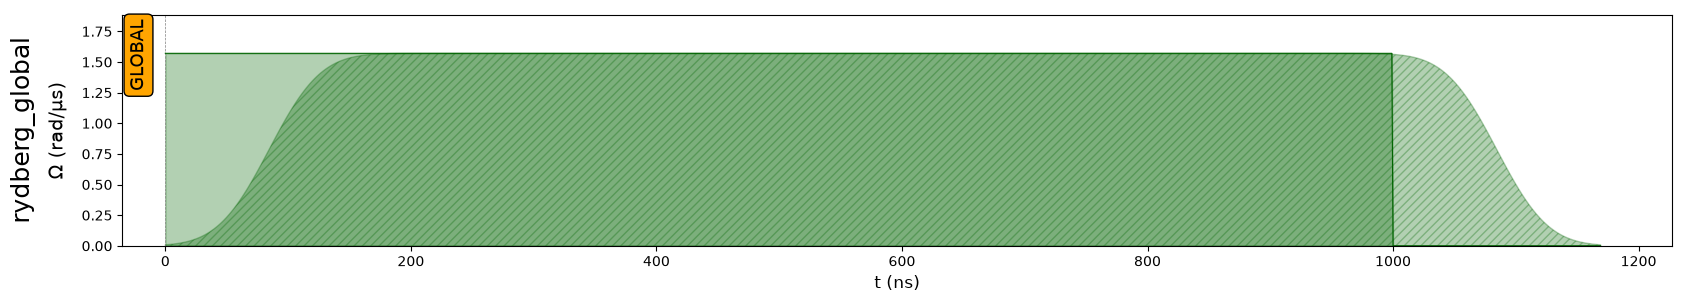

Résultat : Counter({'0': 523, '1': 477})


In [ ]:

import numpy as np
import pulser
from pulser.backends import QutipBackendV2

# 1. Choisir un modèle de dispositif
device = pulser.AnalogDevice

# 2. Créer un registre d'un seul atome
register = pulser.Register.from_coordinates(
    [(0, 0)],
    prefix="q"
)

# 3. Construire la séquence
sequence = pulser.Sequence(register, device)

# 4. Déclarer le canal laser global
sequence.declare_channel(
    "rydberg_global",
    "rydberg_global"
)

# 5. Ajouter une impulsion pi
# Durée : 1000 ns
# Amplitude : pi rad/microseconde
# Désaccord : 0
# Phase : 0
pulse = pulser.Pulse.ConstantPulse(
    1000,
    np.pi,
    0,
    0
)

sequence.add(pulse, "rydberg_global")

# Visualiser la séquence
sequence.draw()

# 6. Simuler localement avec QuTiP
backend = QutipBackendV2(sequence)
result = backend.run()

print("Résultat :", result.final_bitstrings)


Commençons par un seul atome, avec un Hamiltonien :
$
\frac{H(t)}{\hbar} =
\frac{\Omega(t)}{2}X-\Delta(t)n,
\qquad n=|r\rangle\langle r|.
$

Ici, \(X\) couple l'état fondamental \(|g\rangle\) à l'état de Rydberg $r\rangle$

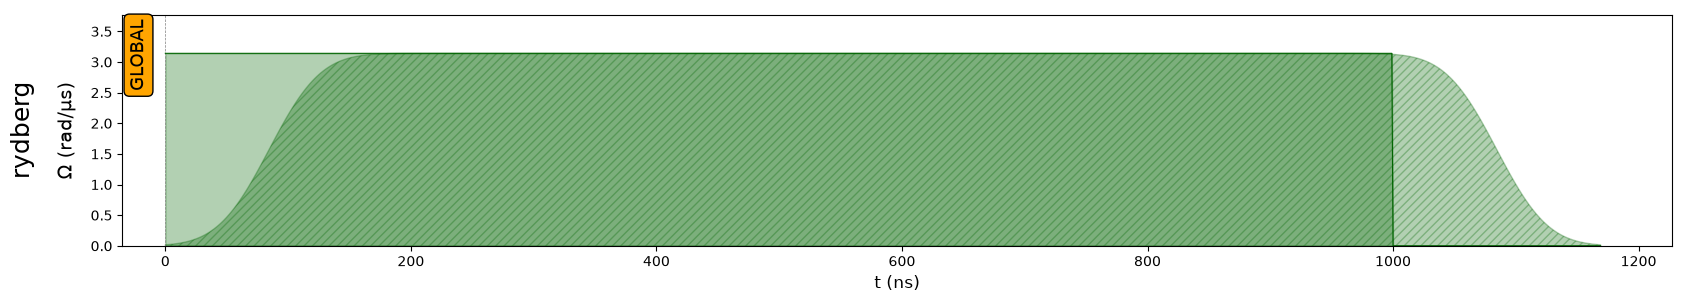

Counter({'1': 1000})


In [5]:

import numpy as np
import pulser
from pulser.backends import QutipBackendV2

# Un atome placé à l'origine
register = pulser.Register.from_coordinates(
    [(0, 0)],
    prefix="q",
)

# Dispositif analogique de Pasqal
sequence = pulser.Sequence(register, pulser.AnalogDevice)

# Canal laser global de transition ground-Rydberg
sequence.declare_channel(
    "rydberg",
    "rydberg_global",
)

# Pulse carré : Omega = pi rad/us, Delta = 0
duration = 1000  # ns
omega = np.pi   # rad/us
delta = 0.0     # rad/us
phase = 0.0     # rad

pulse = pulser.Pulse.ConstantPulse(
    duration,
    omega,
    delta,
    phase,
)

sequence.add(pulse, "rydberg")

sequence.draw()

results = QutipBackendV2(sequence).run()
print(results.final_bitstrings)


Hamiltonien d'interraction : $
H_{\mathrm{int}}
=\sum_{i<j} V_{ij}n_i n_j,
\qquad
V_{ij}=\frac{C_6}{R_{ij}^{6}}.
$

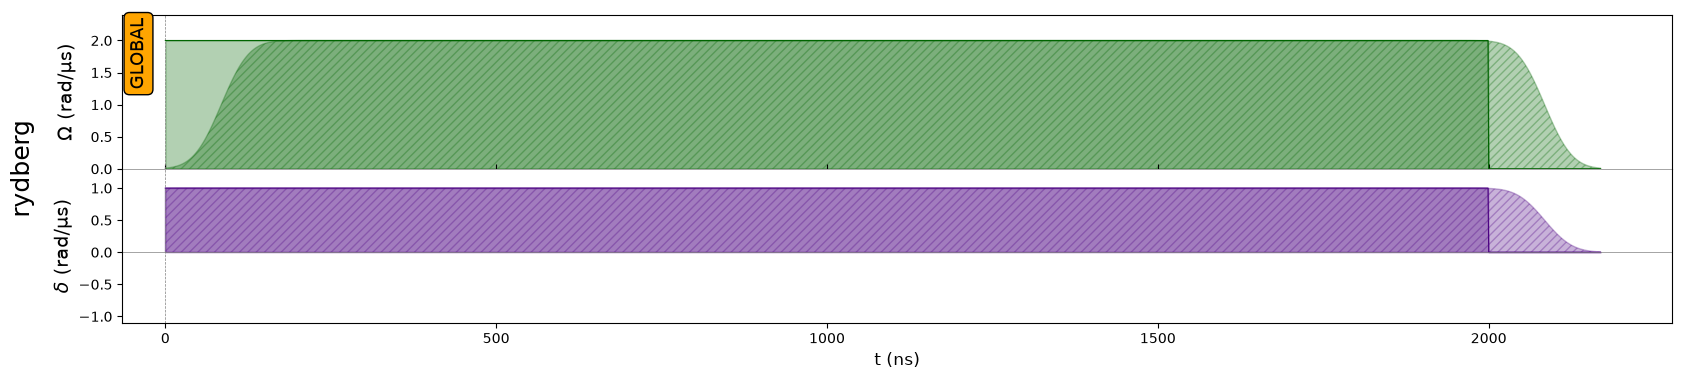

États mesurés : Counter({'11': 499, '01': 239, '10': 227, '00': 35})
État quantique final :
QutipState
----------
Eigenstates: ('r', 'g')
Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[-0.20795682-0.65984617j]
 [-0.46783629-0.16166685j]
 [-0.46783629-0.16166685j]
 [-0.14913615+0.09540161j]]


In [ ]:

import numpy as np
import pulser
from pulser.backends import QutipBackendV2

# Distance entre les deux atomes en micromètres 
distance = 10

register = pulser.Register.from_coordinates(
    [(-distance/2, 0), (distance/2, 0)],  #Position des atomes
    prefix="q",
)

sequence = pulser.Sequence(register, pulser.AnalogDevice)
sequence.declare_channel("rydberg", "rydberg_global")

pulse = pulser.Pulse.ConstantPulse(
    2000,  # ns
    2.0,   # amplitude, rad/us
    1.0,   # detuning, rad/us
    0.0,   # phase, rad
)

sequence.add(pulse, "rydberg")
sequence.draw()

results = QutipBackendV2(sequence).run()

print("États mesurés :", results.final_bitstrings)
print("État quantique final :")
print(results.final_state)
